# 연습문제 05 - RNN 감성분석

/Users/hwangdayoung/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5069 - loss: 0.6956 - val_accuracy: 0.5116 - val_loss: 0.6930
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5266 - loss: 0.6913 - val_accuracy: 0.5238 - val_loss: 0.6908
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5439 - loss: 0.6868 - val_accuracy: 0.5354 - val_loss: 0.6891
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5678 - loss: 0.6827 - val_accuracy: 0.5416 - val_loss: 0.6873
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5837 - loss: 0.6790 - val_accuracy: 0.5500 - val_loss: 0.6856
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5927 - loss: 0.6742 - val_accuracy: 0.5544 - val_loss: 0.6839
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5984 - loss: 0.6717 - val_accuracy: 0.5590 - val_loss: 0.68

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 16)        │         8,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 8)              │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,420 (64.14 KB)

 Trainable params: 8,209 (32.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,211 (32.08 KB)

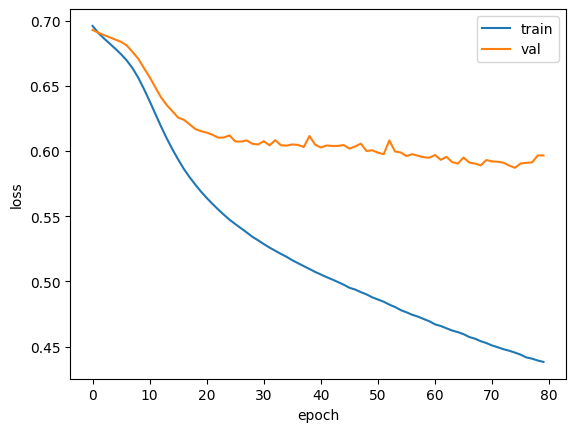

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 992us/step - accuracy: 0.6962 - loss: 0.6016
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Predict Probability =  [[0.4723312]]


In [1]:
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences

(train_input, train_target), (test_input, test_target) = imdb.load_data(num_words=500)
train_input, val_input, train_target, val_target = train_test_split(train_input, train_target, test_size=0.2, random_state=42)

word_id = imdb.get_word_index()  
id_word = dict( [(value, key) for (key, value) in word_id.items()] )  

Seq_length = 100
train_seq = pad_sequences(train_input, maxlen=Seq_length)
val_seq = pad_sequences(val_input, maxlen=Seq_length)
test_seq = pad_sequences(test_input, maxlen=Seq_length)

num_voca = 500
dim_word = 16
dim_hidden = 8

model = keras.Sequential()
model.add(keras.layers.Embedding(num_voca, dim_word))  
model.add(keras.layers.SimpleRNN(dim_hidden))
model.add(keras.layers.Dense(1, activation='sigmoid'))

rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)  
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])
cp = keras.callbacks.ModelCheckpoint('IMDB-RNN-model.keras', save_best_only=True)
es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
history = model.fit(train_seq, train_target, epochs=100, batch_size=64, validation_data=(val_seq, val_target), callbacks=[cp, es])
model.summary()     

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

model.evaluate(test_seq, test_target)

i = 65
new_data = test_seq[i:i+1]
print('Predict Probability = ', model.predict(new_data))

1. 영화 리뷰 데이터셋에 대해 아래의 신경망을 구성하고 그 결과를 정리하시오.

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5208 - loss: 0.7166 - val_accuracy: 0.5974 - val_loss: 0.6697
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5836 - loss: 0.6748 - val_accuracy: 0.6722 - val_loss: 0.6205
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6603 - loss: 0.6234 - val_accuracy: 0.7146 - val_loss: 0.5772
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7019 - loss: 0.5887 - val_accuracy: 0.7288 - val_loss: 0.5482
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7435 - loss: 0.5478 - val_accuracy: 0.7512 - val_loss: 0.5160
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7555 - loss: 0.5265 - val_accuracy: 0.7478 - val_loss: 0.5132
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7712 - loss: 0.5069 - val_accuracy: 0.7614 - val_loss: 0.4949
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7779 - loss: 0.4967 - val_accu

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 80, 12)         │         6,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 80, 8)          │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,628 (49.33 KB)

 Trainable params: 6,313 (24.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,315 (24.67 KB)

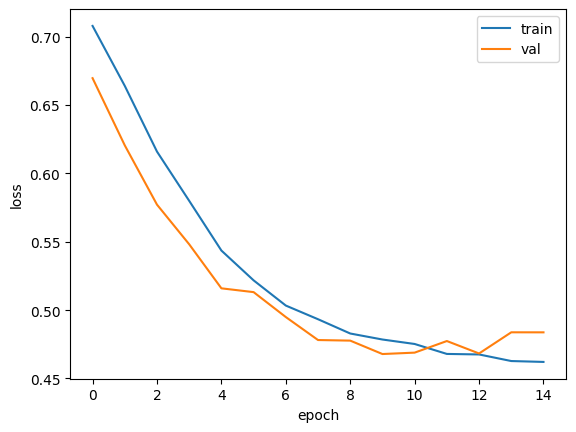

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7860 - loss: 0.4609
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Predict Probability =  [[0.67168486]]


In [ ]:
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences

(train_input, train_target), (test_input, test_target) = imdb.load_data(num_words=500)
train_input, val_input, train_target, val_target = train_test_split(train_input, train_target, test_size=0.2, random_state=42)

word_id = imdb.get_word_index()  
id_word = dict( [(value, key) for (key, value) in word_id.items()] )  

Seq_length = 80
train_seq = pad_sequences(train_input, maxlen=Seq_length)
val_seq = pad_sequences(val_input, maxlen=Seq_length)
test_seq = pad_sequences(test_input, maxlen=Seq_length)

num_voca = 500
dim_word = 12
dim_hidden = 8

model = keras.Sequential()
model.add(keras.layers.Embedding(num_voca, dim_word))
model.add(keras.layers.SimpleRNN(dim_hidden, return_sequences=True))
model.add(keras.layers.Dropout(0.3))
model.add(keras.layers.SimpleRNN(dim_hidden, return_sequences=False))
model.add(keras.layers.Dropout(0.3))
model.add(keras.layers.Dense(1, activation='sigmoid'))

rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)  
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])
cp = keras.callbacks.ModelCheckpoint('IMDB-RNN-model.keras', save_best_only=True)
es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
history = model.fit(train_seq, train_target, epochs=100, batch_size=64, validation_data=(val_seq, val_target), callbacks=[cp, es])
model.summary()     

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

model.evaluate(test_seq, test_target)

i = 65
new_data = test_seq[i:i+1]
print('Predict Probability = ', model.predict(new_data))

In [7]:
i = 65
new_data = test_seq[i:i+1]
print('new_data = ', new_data)
print('test_target = ', test_target[i])
print('Predict Probability = ', model.predict(new_data))

new_data =  [[ 21  61   2   9   4 247   2   2   7   2   2   8   2  59   2  12   4  96
   59   9  19   2   7   2   5   2  33   4 172  58  55   2   2  23  13  62
   82  40   8   2  61   2   5   2  18 347  37 256   6   2 217  13 161  60
  124  59   2 207  64   2  41  18  41 228  38  92   2 101   2   5 140  67
    4  20 490  30   2  11 111   2]]
test_target =  1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Predict Probability =  [[0.67168486]]


2. 다음 코드를 참고해서 질문에 답하시오.

In [8]:
imdb.load_data(num_words=600)
pad_sequences(train_input, maxlen=120)
keras.layers.Embedding(600, 14)
keras.layers.SimpleRNN(12)
rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)  
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])

3. 4개 데이터에 대한 이진분류 모델의 예측치(y_pred)와 실제 레이블(y_true)이 다음과 같을 때, 코드의 결과를 정리하시오.(Binary crossentropy)

In [9]:
import numpy as np

y_true = np.array([1, 1, 0, 0])
y_pred = np.array([0.9, 0.7, 0.2, 0.4])

bce_loss = - (y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

print(y_true)
print(y_pred)
print(bce_loss.round(4))

[1 1 0 0]
[0.9 0.7 0.2 0.4]
[0.1054 0.3567 0.2231 0.5108]


In [14]:
print(dict({ 'i': 0, 'say': 1}))

{'i': 0, 'say': 1}
